# IMPORTACIÓN DE DATOS

> La EDA siguiente es exploratoria. Las transformaciones que aprenden parámetros estadísticos se ajustarán **después del split**, dentro de pipelines entrenados únicamente con cada partición de entrenamiento.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("alumnado/clientes_formacion.csv")

# EDA

In [3]:
df.shape

(3102, 22)

In [4]:
df.columns.tolist()

['id_cliente',
 'edad',
 'provincia',
 'situacion_laboral',
 'canal_captacion',
 'plan',
 'descuento_pct',
 'cuota_mensual_eur',
 'antiguedad_meses',
 'accesos_30d_previos',
 'accesos_30d',
 'dias_activos_30d',
 'horas_uso_30d',
 'dias_desde_ultimo_acceso',
 'cursos_iniciados_30d',
 'cursos_completados_30d',
 'incidencias_soporte_30d',
 'satisfaccion',
 'valoracion_tutor',
 'telefono_secundario',
 'estado_cuenta_31_octubre',
 'abandona']

In [5]:
df.id_cliente.nunique()

3000

In [6]:
df["provincia"].value_counts(dropna=False).sort_values()

provincia
NaN          104
Zaragoza     146
A_Coruna     217
Bizkaia      223
Malaga       240
Sevilla      257
Valencia     328
otra         417
Barcelona    542
Madrid       628
Name: count, dtype: int64

<Axes: ylabel='provincia'>

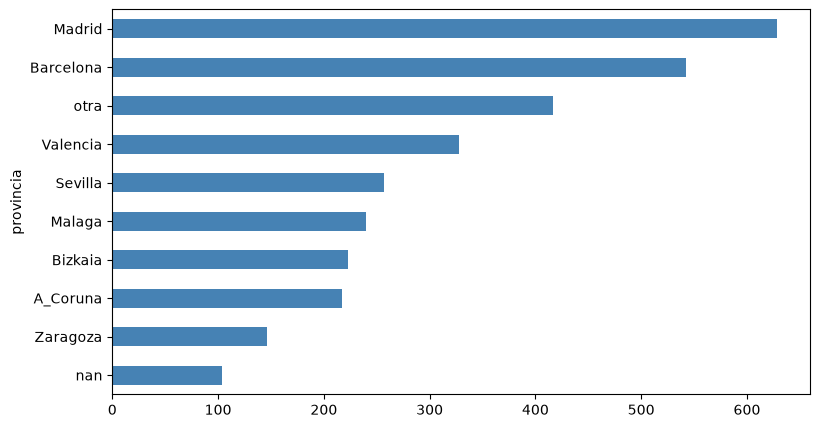

In [7]:
conteo = df["provincia"].value_counts(dropna=False).sort_values()
conteo.plot.barh(figsize=(9, 5), color="steelblue")

<Axes: ylabel='situacion_laboral'>

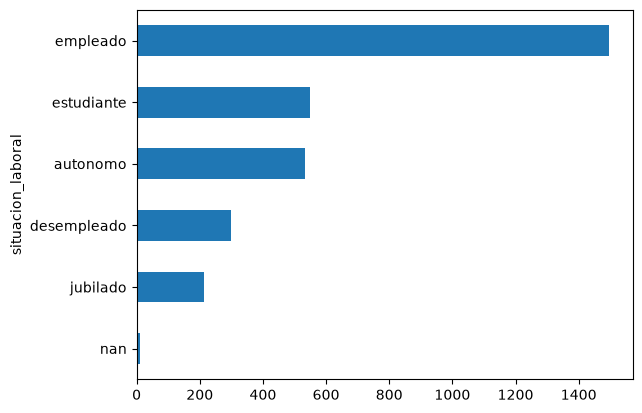

In [8]:
df["situacion_laboral"].value_counts(dropna=False).sort_values().plot.barh()

<Axes: ylabel='canal_captacion'>

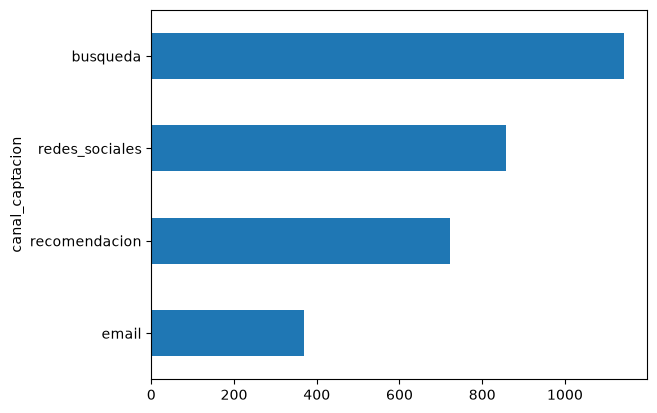

In [9]:
df["canal_captacion"].value_counts().sort_values().plot.barh()

<Axes: ylabel='plan'>

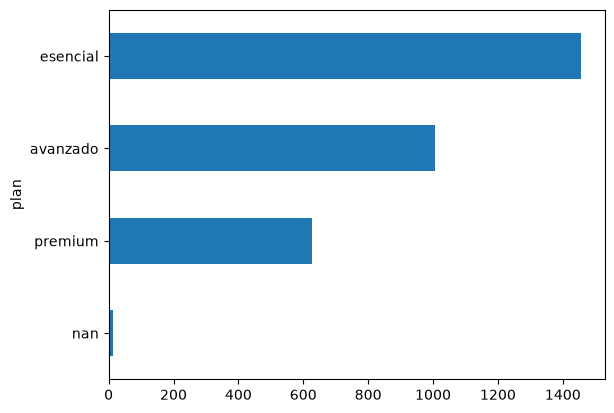

In [10]:
df["plan"].value_counts(dropna=False).sort_values().plot.barh()

<Axes: ylabel='descuento_pct'>

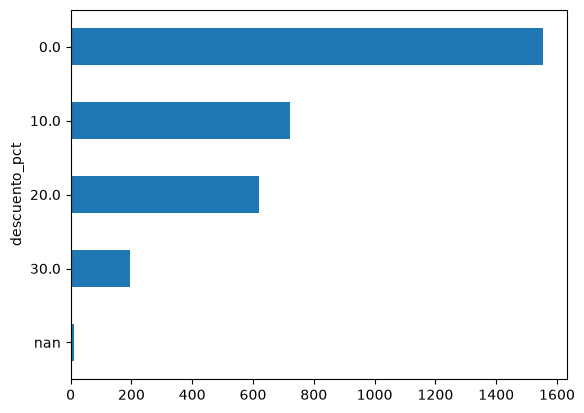

In [11]:
df["descuento_pct"].value_counts(dropna=False).sort_values().plot.barh()

<Axes: ylabel='cuota_mensual_eur'>

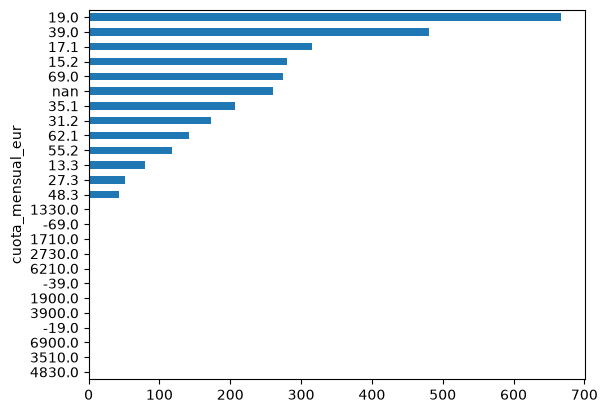

In [12]:
df["cuota_mensual_eur"].value_counts(dropna=False).sort_values().plot.barh()

In [13]:
df["cuota_mensual_eur"].describe()

count    2842.000000
mean       44.574068
std       231.938553
min       -69.000000
25%        19.000000
50%        31.200000
75%        39.000000
max      6900.000000
Name: cuota_mensual_eur, dtype: float64

In [14]:
df["antiguedad_meses"].describe()

count    3090.000000
mean       18.681877
std        12.636337
min         2.000000
25%        10.000000
50%        15.000000
75%        25.000000
max        60.000000
Name: antiguedad_meses, dtype: float64

In [15]:
df["accesos_30d_previos"].describe()

count    3090.000000
mean       16.780583
std        12.199131
min         0.000000
25%         9.000000
50%        14.000000
75%        22.000000
max       129.000000
Name: accesos_30d_previos, dtype: float64

In [16]:
df["accesos_30d_previos"].describe()

count    3090.000000
mean       16.780583
std        12.199131
min         0.000000
25%         9.000000
50%        14.000000
75%        22.000000
max       129.000000
Name: accesos_30d_previos, dtype: float64

<Axes: >

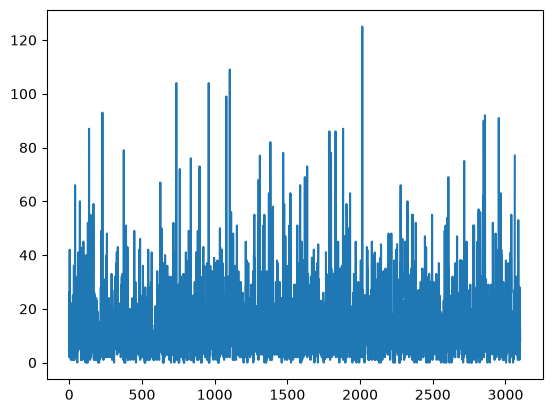

In [17]:
df["accesos_30d"].plot() #####################################

<Axes: >

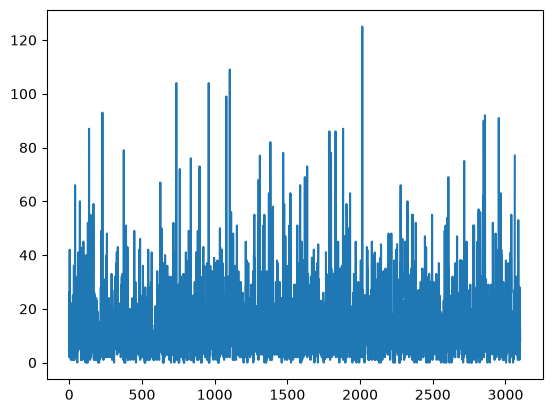

In [18]:
df["accesos_30d"].plot() #####################################

In [19]:
df["dias_activos_30d"].describe() # Días distintos con al menos una sesión. Entre 0 y 30 y no superior a los accesos.

count    3090.000000
mean        9.929450
std         6.559256
min         0.000000
25%         5.000000
50%         9.000000
75%        14.000000
max        30.000000
Name: dias_activos_30d, dtype: float64

<Axes: title={'center': 'Distribución de días activos en los últimos 30 días'}, ylabel='Frequency'>

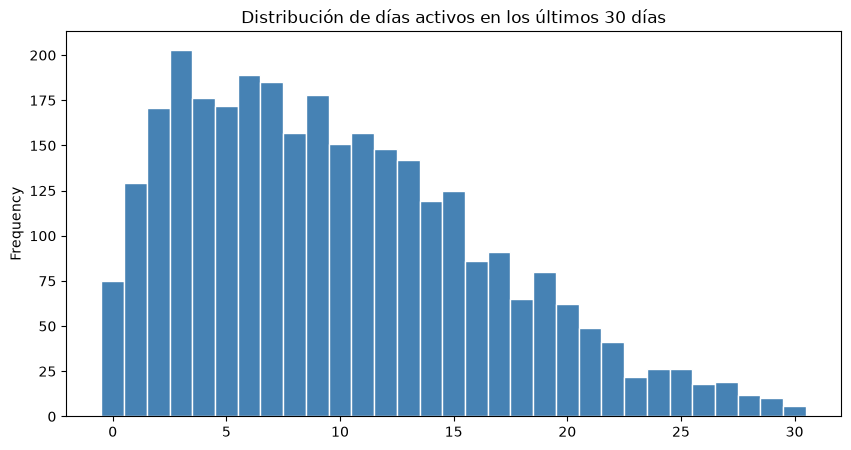

In [20]:
df["dias_activos_30d"].plot.hist(
    bins=[i - 0.5 for i in range(32)],
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
    title="Distribución de días activos en los últimos 30 días"
)

In [21]:
df["horas_uso_30d"].describe()

count    2784.000000
mean       15.910912
std       222.704925
min       -12.000000
25%         2.050000
50%         4.550000
75%         8.892500
max      8000.000000
Name: horas_uso_30d, dtype: float64

In [22]:
df["dias_desde_ultimo_acceso"].describe()

count    3090.000000
mean        5.833010
std         9.047263
min         0.000000
25%         0.000000
50%         2.000000
75%         8.000000
max        58.000000
Name: dias_desde_ultimo_acceso, dtype: float64

<Axes: title={'center': 'Diferencia entre el 30 de septiembre y el día del último acceso. Cero significa acceso el propio día 30. Si no hay accesos recientes, es al menos 30.'}, ylabel='Frequency'>

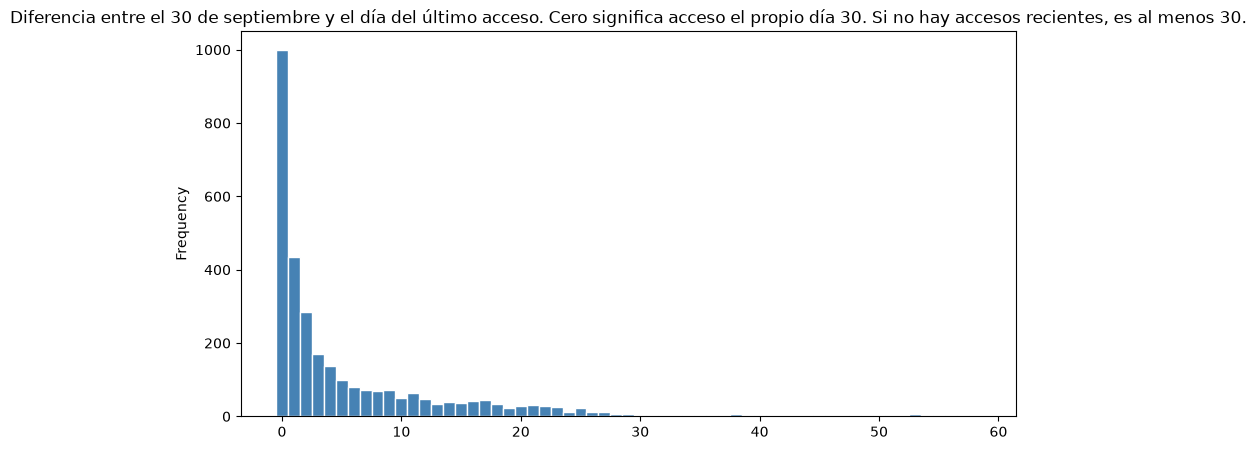

In [23]:
df["dias_desde_ultimo_acceso"].plot.hist(
    bins=[i - 0.5 for i in range(60)],
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
    title="Diferencia entre el 30 de septiembre y el día del último acceso. Cero significa acceso el propio día 30. Si no hay accesos recientes, es al menos 30."
)

In [24]:
df["cursos_iniciados_30d"].describe()

count    3090.000000
mean        1.730097
std         2.074752
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        19.000000
Name: cursos_iniciados_30d, dtype: float64

<Axes: xlabel='cursos_iniciados_30d'>

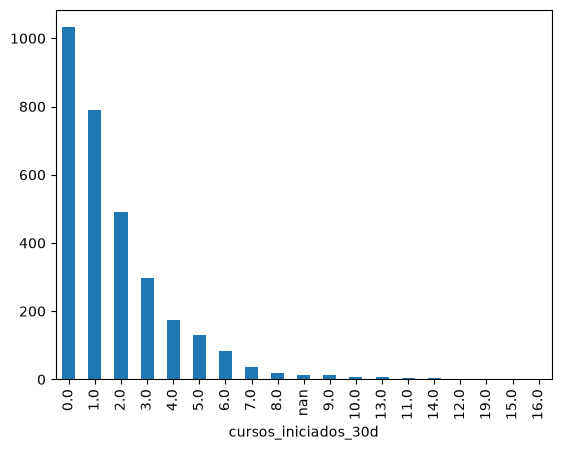

In [25]:
df["cursos_iniciados_30d"].value_counts(dropna=False).sort_values(ascending=False).plot.bar()

In [26]:
df["cursos_completados_30d"].describe()

count    3090.000000
mean        0.810680
std         1.201629
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max        10.000000
Name: cursos_completados_30d, dtype: float64

<Axes: xlabel='cursos_completados_30d'>

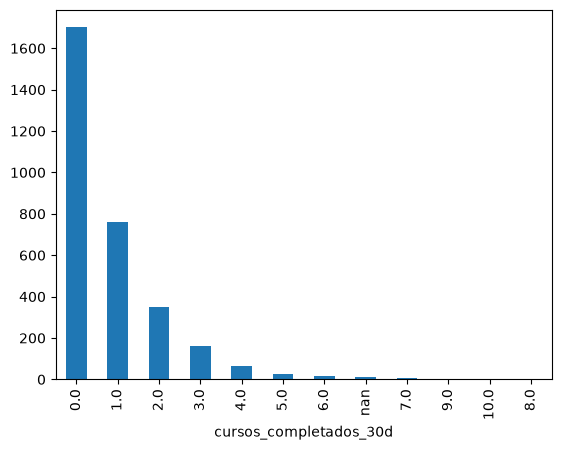

In [27]:
df["cursos_completados_30d"].value_counts(dropna=False).sort_values(ascending=False).plot.bar()

In [28]:
df["incidencias_soporte_30d"].describe()

count    3090.000000
mean        0.449838
std         0.710811
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         5.000000
Name: incidencias_soporte_30d, dtype: float64

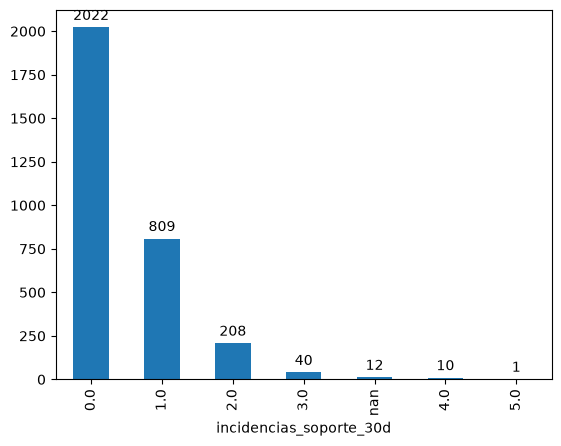

In [29]:
import matplotlib.pyplot as plt

# 1. Generar la gráfica guardando el objeto axes en una variable
ax = df["incidencias_soporte_30d"].value_counts(dropna=False).sort_values(ascending=False).plot.bar()

# 2. Añadir las etiquetas numéricas encima de cada barra
ax.bar_label(ax.containers[0], padding=3)

# Opcional: ajustar límites o mostrar la gráfica
plt.show()

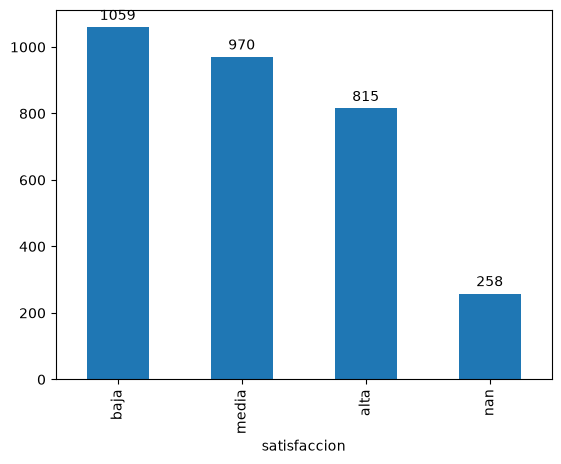

In [30]:
import matplotlib.pyplot as plt

ax = df["satisfaccion"].value_counts(dropna=False).sort_values(ascending=False).plot.bar()
ax.bar_label(ax.containers[0], padding=3)
plt.show()

In [31]:
df["valoracion_tutor"].value_counts(dropna=False)

valoracion_tutor
NaN    2850
4.0       7
4.1       7
4.8       7
6.5       6
       ... 
2.1       1
5.5       1
5.1       1
0.0       1
2.3       1
Name: count, Length: 75, dtype: int64

<Axes: xlabel='valoracion_tutor'>

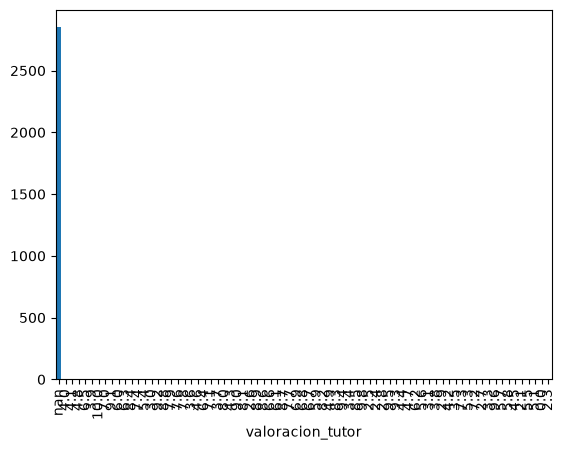

In [32]:
df["valoracion_tutor"].value_counts(dropna=False).sort_values(ascending=False).plot.bar()

<Axes: xlabel='valoracion_tutor'>

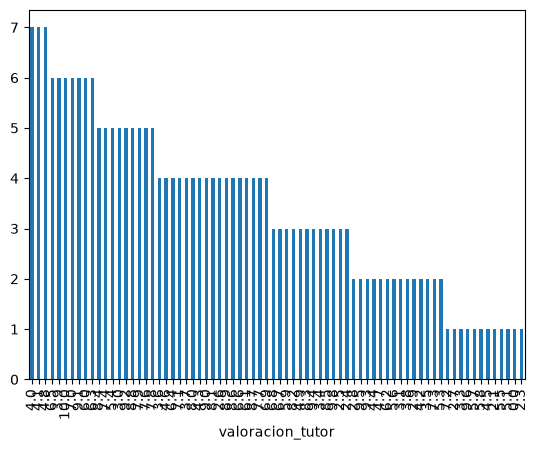

In [33]:
df["valoracion_tutor"].value_counts(dropna=True).sort_values(ascending=False).plot.bar()

In [34]:
df["telefono_secundario"].value_counts(dropna=False)

telefono_secundario
NaN    3102
Name: count, dtype: int64

In [35]:
df.shape

(3102, 22)

In [36]:
df["estado_cuenta_31_octubre"].value_counts(dropna=False)

estado_cuenta_31_octubre
activa    2293
baja       797
NaN         12
Name: count, dtype: int64

In [37]:
df["abandona"].value_counts(dropna=False)

abandona
no     2293
si      797
NaN      12
Name: count, dtype: int64

In [38]:
desc = df.describe()

def resaltar_tabla(df_desc):
    # Inicializar matriz de estilos
    styles = pd.DataFrame('', index=df_desc.index, columns=df_desc.columns)
    
    # 1. Resaltar valores negativos en rojo
    for col in df_desc.columns:
        for idx in df_desc.index:
            if df_desc.loc[idx, col] < 0:
                styles.loc[idx, col] = 'background-color: #ffcccc; color: #990000;'
    
    # 2. Resaltar en amarillo el max si >= 4 * 75%
    for col in df_desc.columns:
        p75 = df_desc.loc['75%', col]
        v_max = df_desc.loc['max', col]
        if p75 != 0 and v_max >= 4 * p75:
            styles.loc['max', col] = 'background-color: #ffff99; color: #000000;'
            
    return styles

# Aplicar estilo al DataFrame
desc.style.apply(resaltar_tabla, axis=None).format(precision=2)

,edad,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,valoracion_tutor,telefono_secundario
count,2724.00,3090.00,2842.00,3090.00,3090.00,3090.00,3090.00,2784.00,3090.00,3090.00,3090.00,3090.00,252.00,0.00
mean,38.47,8.24,44.57,18.68,16.78,14.29,9.93,15.91,5.83,1.73,0.81,0.45,6.28,nan
std,16.60,9.62,231.94,12.64,12.20,13.45,6.56,222.70,9.05,2.07,1.20,0.71,2.21,nan
min,-12.00,0.00,-69.00,2.00,0.00,0.00,0.00,-12.00,0.00,0.00,0.00,0.00,0.00,nan
25%,27.00,0.00,19.00,10.00,9.00,5.00,5.00,2.05,0.00,0.00,0.00,0.00,4.28,nan
50%,37.00,0.00,31.20,15.00,14.00,11.00,9.00,4.55,2.00,1.00,0.00,0.00,6.50,nan
75%,45.00,20.00,39.00,25.00,22.00,19.00,14.00,8.89,8.00,3.00,1.00,1.00,8.12,nan
max,250.00,30.00,6900.00,60.00,129.00,125.00,30.00,8000.00,58.00,19.00,10.00,5.00,10.00,nan


In [39]:
df.duplicated().value_counts()

False    3001
True      101
Name: count, dtype: int64

In [40]:
df.head()

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,...,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,valoracion_tutor,telefono_secundario,estado_cuenta_31_octubre,abandona
0,CL000072,25.0,Madrid,desempleado,recomendacion,avanzado,20.0,31.2,16.0,62.0,...,12.66,13.0,2.0,2.0,1.0,baja,NaN,NaN,activa,no
1,CL001658,53.0,Madrid,empleado,busqueda,esencial,10.0,17.1,7.0,21.0,...,1.44,23.0,0.0,0.0,0.0,NaN,NaN,NaN,baja,si
2,CL001805,36.0,Malaga,desempleado,email,esencial,30.0,13.3,6.0,10.0,...,5.24,0.0,2.0,1.0,1.0,media,NaN,NaN,activa,no
3,CL000160,25.0,Zaragoza,estudiante,recomendacion,avanzado,0.0,39.0,35.0,34.0,...,17.86,0.0,4.0,2.0,0.0,alta,NaN,NaN,activa,no
4,CL000753,41.0,Sevilla,empleado,email,esencial,20.0,15.2,21.0,9.0,...,2.19,11.0,1.0,1.0,1.0,baja,NaN,NaN,baja,si


In [41]:
# Eliminación exacta de duplicados: regla determinista, no calcula estadísticas.
########################
########################
########################
df = df.drop_duplicates(keep='first').copy()

In [42]:
df

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,...,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,valoracion_tutor,telefono_secundario,estado_cuenta_31_octubre,abandona
0,CL000072,25.0,Madrid,desempleado,recomendacion,avanzado,20.0,31.2,16.0,62.0,...,12.66,13.0,2.0,2.0,1.0,baja,NaN,NaN,activa,no
1,CL001658,53.0,Madrid,empleado,busqueda,esencial,10.0,17.1,7.0,21.0,...,1.44,23.0,0.0,0.0,0.0,NaN,NaN,NaN,baja,si
2,CL001805,36.0,Malaga,desempleado,email,esencial,30.0,13.3,6.0,10.0,...,5.24,0.0,2.0,1.0,1.0,media,NaN,NaN,activa,no
3,CL000160,25.0,Zaragoza,estudiante,recomendacion,avanzado,0.0,39.0,35.0,34.0,...,17.86,0.0,4.0,2.0,0.0,alta,NaN,NaN,activa,no
4,CL000753,41.0,Sevilla,empleado,email,esencial,20.0,15.2,21.0,9.0,...,2.19,11.0,1.0,1.0,1.0,baja,NaN,NaN,baja,si
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3097,CL001182,30.0,otra,empleado,busqueda,avanzado,0.0,39.0,17.0,18.0,...,1.84,4.0,1.0,0.0,0.0,baja,NaN,NaN,baja,si
3098,CL002274,33.0,Madrid,empleado,recomendacion,avanzado,10.0,NaN,3.0,10.0,...,12.36,1.0,5.0,4.0,1.0,alta,NaN,NaN,activa,no
3099,CL002319,60.0,Madrid,jubilado,redes_sociales,premium,10.0,62.1,9.0,17.0,...,14.48,0.0,2.0,2.0,1.0,baja,NaN,NaN,activa,no
3100,CL002851,41.0,Bizkaia,empleado,busqueda,premium,20.0,55.2,12.0,30.0,...,5.40,6.0,1.0,1.0,0.0,alta,10.0,NaN,activa,no


In [43]:
# No se puede entrenar con la etiqueta desconocida.
########################
########################
########################
df = df.loc[df['abandona'].notna()].copy()

In [44]:
df.shape

(3000, 22)

In [45]:
# AUDITORÍA DE TARGET LEAKAGE (solo exploración; no usar para imputar ni filtrar).
# El estado de 31 de octubre coincide exactamente con la etiqueta abandona.
########################
########################
########################
fuga_check = pd.crosstab(df['estado_cuenta_31_octubre'], df['abandona'], normalize='index') * 100
print(fuga_check)

abandona                     no     si
estado_cuenta_31_octubre              
activa                    100.0    0.0
baja                        0.0  100.0


In [46]:
# Esta columna está disponible DESPUÉS del periodo de predicción y desvela el target.
# No filtramos por sus nulos: eso también utilizaría información futura.
########################
########################
########################
df = df.drop(columns=['estado_cuenta_31_octubre'])

In [47]:
df = df.drop(columns="telefono_secundario")

In [48]:
df.shape

(3000, 20)

In [49]:
df = df.drop(columns="valoracion_tutor")

In [50]:
df.shape

(3000, 19)

In [51]:
df[df.edad >75]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona
147,CL002973,200.0,Zaragoza,empleado,recomendacion,esencial,0.0,19.0,25.0,5.0,3.0,3.0,0.72,0.0,0.0,0.0,0.0,media,no
274,CL002808,220.0,Barcelona,estudiante,busqueda,premium,20.0,55.2,8.0,34.0,12.0,9.0,6.98,14.0,0.0,0.0,1.0,baja,si
400,CL002842,77.0,Madrid,jubilado,busqueda,esencial,0.0,19.0,31.0,29.0,43.0,23.0,12.73,1.0,6.0,4.0,2.0,media,no
670,CL000976,175.0,Malaga,empleado,busqueda,avanzado,0.0,39.0,4.0,31.0,10.0,10.0,4.01,13.0,2.0,1.0,1.0,alta,no
693,CL000549,79.0,Bizkaia,jubilado,recomendacion,avanzado,0.0,39.0,17.0,15.0,9.0,7.0,6.12,3.0,1.0,1.0,0.0,media,no
835,CL001633,76.0,Madrid,jubilado,busqueda,esencial,0.0,NaN,17.0,7.0,2.0,2.0,0.85,9.0,0.0,0.0,0.0,baja,no
853,CL002228,79.0,Madrid,jubilado,busqueda,esencial,10.0,17.1,25.0,66.0,25.0,15.0,7.78,1.0,1.0,0.0,0.0,media,no
939,CL000768,180.0,Barcelona,empleado,busqueda,esencial,0.0,19.0,36.0,4.0,2.0,2.0,0.66,23.0,0.0,0.0,0.0,alta,si
1004,CL001289,78.0,otra,jubilado,busqueda,esencial,0.0,19.0,18.0,4.0,9.0,8.0,3.02,2.0,1.0,1.0,0.0,baja,no
1040,CL002518,77.0,Bizkaia,jubilado,busqueda,avanzado,20.0,31.2,7.0,21.0,29.0,18.0,15.91,1.0,3.0,0.0,0.0,media,no


In [52]:
import numpy as np

# Edad fuera de los límites de negocio: convertir en NaN (NO calcular todavía medianas).
# Se usará la mediana de situacion_laboral aprendida SOLO en el train de cada fold.
########################
########################
########################
condicion_outlier = (df['edad'] < 18) | (df['edad'] > 100)
print('Edades fuera de rango:', condicion_outlier.sum())
df.loc[condicion_outlier, 'edad'] = np.nan

Edades fuera de rango: 12


**Imputación de edad aplazada:** la mediana por `situacion_laboral` se calculará en `fit()` del transformador del pipeline. Por tanto, ni el test ni la partición de validación participarán en ese cálculo. La edad faltante también se imputará allí.

In [53]:
# Comprobar edades que necesitarán imputación, sin utilizar estadísticas del dataset completo.
########################
########################
########################
df['edad'].isna().sum()

np.int64(372)

In [54]:
df.describe().style.apply(resaltar_tabla, axis=None).format(precision=2)

,edad,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d
count,2628.00,3000.00,2760.00,3000.00,3000.00,3000.00,3000.00,2700.00,3000.00,3000.00,3000.00,3000.00
mean,37.96,8.26,44.47,18.68,16.80,14.33,9.93,16.22,5.80,1.73,0.81,0.45
std,13.39,9.64,234.05,12.62,12.25,13.51,6.56,226.13,8.97,2.08,1.20,0.71
min,18.00,0.00,-69.00,2.00,0.00,0.00,0.00,-12.00,0.00,0.00,0.00,0.00
25%,27.00,0.00,19.00,10.00,9.00,5.00,5.00,2.05,0.00,0.00,0.00,0.00
50%,37.00,0.00,31.20,15.00,14.00,11.00,9.00,4.55,2.00,1.00,0.00,0.00
75%,45.00,20.00,39.00,25.00,22.00,19.00,14.00,8.91,8.00,3.00,1.00,1.00
max,80.00,30.00,6900.00,60.00,129.00,125.00,30.00,8000.00,58.00,19.00,10.00,5.00


In [55]:
df.isnull().sum()

id_cliente                    0
edad                        372
provincia                    90
situacion_laboral             0
canal_captacion               0
plan                          0
descuento_pct                 0
cuota_mensual_eur           240
antiguedad_meses              0
accesos_30d_previos           0
accesos_30d                   0
dias_activos_30d              0
horas_uso_30d               300
dias_desde_ultimo_acceso      0
cursos_iniciados_30d          0
cursos_completados_30d        0
incidencias_soporte_30d       0
satisfaccion                240
abandona                      0
dtype: int64

<Axes: xlabel='abandona'>

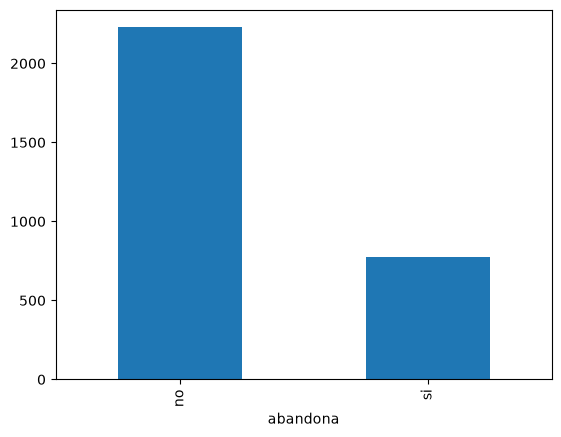

In [56]:
df.abandona.value_counts(dropna=False).plot.bar()

In [57]:
df.satisfaccion.unique()

<ArrowStringArray>
['baja', nan, 'media', 'alta']
Length: 4, dtype: str

In [58]:
# Mapeo FIJO por semántica conocida, independiente del dataset: puede realizarse antes del split.
########################
########################
########################
orden_mapeo = {'baja': 1, 'media': 2, 'alta': 3}
df['satisfaccion'] = df['satisfaccion'].map(orden_mapeo)

In [59]:
# Devuelve True si hay al menos un nombre de columna duplicado
tiene_duplicadas = df.columns.duplicated().any()
print("¿Hay nombres duplicados?", tiene_duplicadas)

# Para ver cuáles son los nombres repetidos:
nombres_duplicados = df.columns[df.columns.duplicated()].tolist()
print("Nombres duplicados:", nombres_duplicados)

¿Hay nombres duplicados? False
Nombres duplicados: []


In [60]:
df.describe().style.apply(resaltar_tabla, axis=None).format(precision=2)

,edad,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion
count,2628.00,3000.00,2760.00,3000.00,3000.00,3000.00,3000.00,2700.00,3000.00,3000.00,3000.00,3000.00,2760.00
mean,37.96,8.26,44.47,18.68,16.80,14.33,9.93,16.22,5.80,1.73,0.81,0.45,1.92
std,13.39,9.64,234.05,12.62,12.25,13.51,6.56,226.13,8.97,2.08,1.20,0.71,0.81
min,18.00,0.00,-69.00,2.00,0.00,0.00,0.00,-12.00,0.00,0.00,0.00,0.00,1.00
25%,27.00,0.00,19.00,10.00,9.00,5.00,5.00,2.05,0.00,0.00,0.00,0.00,1.00
50%,37.00,0.00,31.20,15.00,14.00,11.00,9.00,4.55,2.00,1.00,0.00,0.00,2.00
75%,45.00,20.00,39.00,25.00,22.00,19.00,14.00,8.91,8.00,3.00,1.00,1.00,3.00
max,80.00,30.00,6900.00,60.00,129.00,125.00,30.00,8000.00,58.00,19.00,10.00,5.00,3.00


In [61]:
df.cuota_mensual_eur.unique()

array([  31.2,   17.1,   13.3,   39. ,   15.2,    nan,   69. ,   19. ,
         35.1,   62.1,   27.3,   48.3,   55.2, 3510. , 4830. ,  -69. ,
        -39. , 1900. , 3900. ,  -19. , 1330. , 6900. , 1710. , 2730. ,
       6210. ])

In [62]:
df.descuento_pct.unique()

array([20., 10., 30.,  0.])

In [63]:
df.plan.unique()

<ArrowStringArray>
['avanzado', 'esencial', 'premium']
Length: 3, dtype: str

In [64]:
# Codificación ordinal FIJA, no aprendida de la distribución de los datos.
########################
########################
########################
orden_mapeo = {'esencial': 1, 'avanzado': 2, 'premium': 3}
df['plan'] = df['plan'].map(orden_mapeo)

In [65]:
df.isnull().sum()

id_cliente                    0
edad                        372
provincia                    90
situacion_laboral             0
canal_captacion               0
plan                          0
descuento_pct                 0
cuota_mensual_eur           240
antiguedad_meses              0
accesos_30d_previos           0
accesos_30d                   0
dias_activos_30d              0
horas_uso_30d               300
dias_desde_ultimo_acceso      0
cursos_iniciados_30d          0
cursos_completados_30d        0
incidencias_soporte_30d       0
satisfaccion                240
abandona                      0
dtype: int64

In [66]:
# La edad se imputará dentro de cada fold del pipeline, no aquí.
########################
########################
########################
df[['edad', 'situacion_laboral']].isnull().sum()

edad                 372
situacion_laboral      0
dtype: int64

In [67]:
df.isnull().sum()

id_cliente                    0
edad                        372
provincia                    90
situacion_laboral             0
canal_captacion               0
plan                          0
descuento_pct                 0
cuota_mensual_eur           240
antiguedad_meses              0
accesos_30d_previos           0
accesos_30d                   0
dias_activos_30d              0
horas_uso_30d               300
dias_desde_ultimo_acceso      0
cursos_iniciados_30d          0
cursos_completados_30d        0
incidencias_soporte_30d       0
satisfaccion                240
abandona                      0
dtype: int64

In [68]:
df[df.satisfaccion.isnull()]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona
1,CL001658,53.0,Madrid,empleado,busqueda,1,10.0,17.1,7.0,21.0,2.0,2.0,1.44,23.0,0.0,0.0,0.0,NaN,si
7,CL001525,19.0,Madrid,estudiante,recomendacion,3,0.0,69.0,23.0,16.0,14.0,11.0,13.39,2.0,1.0,0.0,1.0,NaN,no
33,CL001942,31.0,Barcelona,desempleado,busqueda,2,0.0,39.0,7.0,11.0,9.0,9.0,5.21,0.0,1.0,1.0,1.0,NaN,no
38,CL002674,NaN,Valencia,autonomo,busqueda,2,0.0,NaN,42.0,17.0,14.0,11.0,6.96,2.0,2.0,0.0,0.0,NaN,no
45,CL000006,30.0,A_Coruna,empleado,recomendacion,3,0.0,69.0,9.0,14.0,11.0,9.0,6.77,2.0,2.0,1.0,0.0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3000,CL002833,19.0,Sevilla,estudiante,busqueda,2,20.0,31.2,14.0,9.0,9.0,7.0,7.31,3.0,1.0,1.0,0.0,NaN,no
3024,CL002832,28.0,Barcelona,estudiante,redes_sociales,1,30.0,13.3,11.0,17.0,27.0,18.0,9.44,0.0,2.0,0.0,0.0,NaN,no
3055,CL001332,38.0,A_Coruna,autonomo,redes_sociales,1,0.0,19.0,36.0,10.0,1.0,1.0,0.30,12.0,0.0,0.0,1.0,NaN,no
3072,CL001323,28.0,Barcelona,desempleado,busqueda,1,0.0,19.0,7.0,7.0,9.0,8.0,3.71,5.0,0.0,0.0,0.0,NaN,no


In [69]:
# NO IMPUTAR satisfacción a partir de estado_cuenta_31_octubre.
# Esa variable es posterior y equivale al target; usarla aquí filtraría la respuesta.
# La satisfacción faltante se imputará usando únicamente X_train, dentro de Pipeline.
########################
########################
########################
print('Satisfacciones pendientes de imputar:', df['satisfaccion'].isna().sum())

Satisfacciones pendientes de imputar: 240


In [70]:
df.shape

(3000, 19)

In [71]:
df.satisfaccion.value_counts(dropna=False)

satisfaccion
1.0    1025
2.0     942
3.0     793
NaN     240
Name: count, dtype: int64

In [72]:
df.isnull().sum()

id_cliente                    0
edad                        372
provincia                    90
situacion_laboral             0
canal_captacion               0
plan                          0
descuento_pct                 0
cuota_mensual_eur           240
antiguedad_meses              0
accesos_30d_previos           0
accesos_30d                   0
dias_activos_30d              0
horas_uso_30d               300
dias_desde_ultimo_acceso      0
cursos_iniciados_30d          0
cursos_completados_30d        0
incidencias_soporte_30d       0
satisfaccion                240
abandona                      0
dtype: int64

In [73]:
# El estado posterior ya fue excluido en la celda de auditoría.
########################
########################
########################
assert 'estado_cuenta_31_octubre' not in df.columns

In [74]:
df.shape

(3000, 19)

In [75]:
df.isnull().sum()

id_cliente                    0
edad                        372
provincia                    90
situacion_laboral             0
canal_captacion               0
plan                          0
descuento_pct                 0
cuota_mensual_eur           240
antiguedad_meses              0
accesos_30d_previos           0
accesos_30d                   0
dias_activos_30d              0
horas_uso_30d               300
dias_desde_ultimo_acceso      0
cursos_iniciados_30d          0
cursos_completados_30d        0
incidencias_soporte_30d       0
satisfaccion                240
abandona                      0
dtype: int64

In [76]:
# Reemplazo por valor literal fijo: no aprende una estadística y no provoca leakage.
########################
########################
########################
df['provincia'] = df['provincia'].fillna('otra')

In [77]:
df.isnull().sum()

id_cliente                    0
edad                        372
provincia                     0
situacion_laboral             0
canal_captacion               0
plan                          0
descuento_pct                 0
cuota_mensual_eur           240
antiguedad_meses              0
accesos_30d_previos           0
accesos_30d                   0
dias_activos_30d              0
horas_uso_30d               300
dias_desde_ultimo_acceso      0
cursos_iniciados_30d          0
cursos_completados_30d        0
incidencias_soporte_30d       0
satisfaccion                240
abandona                      0
dtype: int64

In [78]:
df.describe().style.apply(resaltar_tabla, axis=None).format(precision=2)

,edad,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion
count,2628.00,3000.00,3000.00,2760.00,3000.00,3000.00,3000.00,3000.00,2700.00,3000.00,3000.00,3000.00,3000.00,2760.00
mean,37.96,1.73,8.26,44.47,18.68,16.80,14.33,9.93,16.22,5.80,1.73,0.81,0.45,1.92
std,13.39,0.78,9.64,234.05,12.62,12.25,13.51,6.56,226.13,8.97,2.08,1.20,0.71,0.81
min,18.00,1.00,0.00,-69.00,2.00,0.00,0.00,0.00,-12.00,0.00,0.00,0.00,0.00,1.00
25%,27.00,1.00,0.00,19.00,10.00,9.00,5.00,5.00,2.05,0.00,0.00,0.00,0.00,1.00
50%,37.00,2.00,0.00,31.20,15.00,14.00,11.00,9.00,4.55,2.00,1.00,0.00,0.00,2.00
75%,45.00,2.00,20.00,39.00,25.00,22.00,19.00,14.00,8.91,8.00,3.00,1.00,1.00,3.00
max,80.00,3.00,30.00,6900.00,60.00,129.00,125.00,30.00,8000.00,58.00,19.00,10.00,5.00,3.00


In [79]:
df.describe().style.apply(resaltar_tabla, axis=None).format(precision=2)

,edad,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion
count,2628.00,3000.00,3000.00,2760.00,3000.00,3000.00,3000.00,3000.00,2700.00,3000.00,3000.00,3000.00,3000.00,2760.00
mean,37.96,1.73,8.26,44.47,18.68,16.80,14.33,9.93,16.22,5.80,1.73,0.81,0.45,1.92
std,13.39,0.78,9.64,234.05,12.62,12.25,13.51,6.56,226.13,8.97,2.08,1.20,0.71,0.81
min,18.00,1.00,0.00,-69.00,2.00,0.00,0.00,0.00,-12.00,0.00,0.00,0.00,0.00,1.00
25%,27.00,1.00,0.00,19.00,10.00,9.00,5.00,5.00,2.05,0.00,0.00,0.00,0.00,1.00
50%,37.00,2.00,0.00,31.20,15.00,14.00,11.00,9.00,4.55,2.00,1.00,0.00,0.00,2.00
75%,45.00,2.00,20.00,39.00,25.00,22.00,19.00,14.00,8.91,8.00,3.00,1.00,1.00,3.00
max,80.00,3.00,30.00,6900.00,60.00,129.00,125.00,30.00,8000.00,58.00,19.00,10.00,5.00,3.00


In [80]:
df[(df.horas_uso_30d < 0) | (df.horas_uso_30d > 90)]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona
165,CL001225,45.0,otra,desempleado,redes_sociales,2,0.0,39.0,13.0,39.0,39.0,22.0,1200.0,0.0,4.0,3.0,1.0,2.0,no
891,CL001467,35.0,Barcelona,desempleado,recomendacion,1,0.0,19.0,11.0,3.0,9.0,8.0,2500.0,0.0,5.0,1.0,1.0,2.0,no
945,CL000327,22.0,A_Coruna,estudiante,redes_sociales,3,0.0,69.0,11.0,14.0,15.0,11.0,-5.0,6.0,1.0,1.0,2.0,1.0,si
1166,CL002052,21.0,otra,estudiante,redes_sociales,2,10.0,35.1,11.0,8.0,9.0,8.0,-2.0,0.0,1.0,0.0,0.0,3.0,no
1241,CL002359,59.0,Malaga,empleado,redes_sociales,1,10.0,17.1,5.0,8.0,3.0,3.0,-12.0,19.0,0.0,0.0,0.0,NaN,si
1247,CL001068,50.0,Bizkaia,empleado,recomendacion,2,20.0,31.2,60.0,17.0,14.0,10.0,-3.0,2.0,1.0,1.0,1.0,1.0,no
1707,CL000740,38.0,Zaragoza,empleado,busqueda,2,0.0,39.0,9.0,34.0,14.0,11.0,900.0,5.0,1.0,0.0,1.0,1.0,si
1723,CL002893,43.0,Bizkaia,autonomo,recomendacion,2,0.0,39.0,60.0,18.0,11.0,8.0,8000.0,1.0,1.0,0.0,0.0,2.0,no
1759,CL000891,22.0,A_Coruna,estudiante,email,1,0.0,19.0,12.0,11.0,19.0,14.0,1600.0,0.0,2.0,0.0,0.0,1.0,no
1812,CL000905,35.0,otra,empleado,busqueda,3,0.0,69.0,25.0,30.0,6.0,6.0,1400.0,5.0,1.0,0.0,0.0,2.0,si


In [81]:
# Límites físicos fijados previamente (0–720 h por 30 días); no se estiman con el dataset.
# La mediana por plan se aprenderá después del split, en cada fold del pipeline.
########################
########################
########################
limite_inferior = 0
limite_superior = 720
fuera_de_rango = ~df['horas_uso_30d'].between(limite_inferior, limite_superior) & df['horas_uso_30d'].notna()
print('Horas fuera de rango:', fuera_de_rango.sum())
df.loc[fuera_de_rango, 'horas_uso_30d'] = np.nan

Horas fuera de rango: 12


<Axes: ylabel='Frequency'>

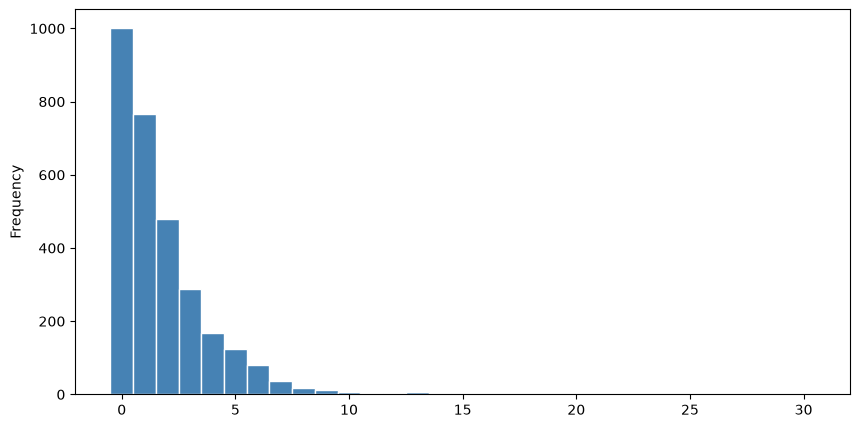

In [82]:
df["cursos_iniciados_30d"].plot.hist(
    bins=[i - 0.5 for i in range(32)],
    figsize=(10, 5),
    color="steelblue",
    edgecolor="white",
)

In [83]:
cursos_pendientes_septiembre = (
    df["cursos_iniciados_30d"] - df["cursos_completados_30d"]
)

cursos_pendientes_septiembre.describe()

count    3000.000000
mean        0.918667
std         1.244415
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max        10.000000
dtype: float64

In [84]:
# Reglas de coherencia FIJAS, no deducidas de train/test.
# Cuando falta un valor, no descartamos la fila: se imputará posteriormente.
########################
########################
########################
df['check_completados'] = (df['cursos_completados_30d'].isna() | df['cursos_iniciados_30d'].isna() |
                           (df['cursos_completados_30d'] <= df['cursos_iniciados_30d']))
df['check_iniciados'] = (df['cursos_iniciados_30d'].isna() | df['accesos_30d'].isna() |
                        (df['cursos_iniciados_30d'] <= df['accesos_30d']))
df['check_horas'] = (df['horas_uso_30d'].isna() | df['cursos_completados_30d'].isna() |
                     (df['horas_uso_30d'] >= 2 * df['cursos_completados_30d']))

In [85]:
df[~df["check_completados"] | ~df["check_iniciados"] | ~df["check_horas"]]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,...,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona,check_completados,check_iniciados,check_horas


In [86]:
# Mantener la decisión original de eliminar incoherencias, pero sin imputaciones aprendidas.
# Solo se eliminan filas con una inconsistencia comprobable en los datos observados.
########################
########################
########################
df = df.loc[df['check_completados'] & df['check_iniciados'] & df['check_horas']].copy()

In [87]:
df.shape

(3000, 22)

In [88]:
df.describe().style.apply(resaltar_tabla, axis=None).format(precision=2)

,edad,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion
count,2628.00,3000.00,3000.00,2760.00,3000.00,3000.00,3000.00,3000.00,2688.00,3000.00,3000.00,3000.00,3000.00,2760.00
mean,37.96,1.73,8.26,44.47,18.68,16.80,14.33,9.93,6.66,5.80,1.73,0.81,0.45,1.92
std,13.39,0.78,9.64,234.05,12.62,12.25,13.51,6.56,7.17,8.97,2.08,1.20,0.71,0.81
min,18.00,1.00,0.00,-69.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
25%,27.00,1.00,0.00,19.00,10.00,9.00,5.00,5.00,2.05,0.00,0.00,0.00,0.00,1.00
50%,37.00,2.00,0.00,31.20,15.00,14.00,11.00,9.00,4.54,2.00,1.00,0.00,0.00,2.00
75%,45.00,2.00,20.00,39.00,25.00,22.00,19.00,14.00,8.87,8.00,3.00,1.00,1.00,3.00
max,80.00,3.00,30.00,6900.00,60.00,129.00,125.00,30.00,74.36,58.00,19.00,10.00,5.00,3.00


In [89]:
df[df.incidencias_soporte_30d>3]

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,...,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona,check_completados,check_iniciados,check_horas
589,CL000624,33.0,otra,empleado,redes_sociales,1,10.0,17.1,6.0,9.0,...,NaN,2.0,1.0,1.0,4.0,2.0,no,True,True,True
749,CL001592,29.0,Barcelona,empleado,busqueda,1,0.0,19.0,4.0,28.0,...,7.33,1.0,3.0,1.0,4.0,3.0,si,True,True,True
873,CL001978,30.0,A_Coruna,empleado,busqueda,1,20.0,15.2,31.0,26.0,...,12.12,0.0,5.0,3.0,4.0,1.0,si,True,True,True
1383,CL000794,NaN,Madrid,jubilado,redes_sociales,3,20.0,55.2,34.0,59.0,...,57.61,0.0,3.0,1.0,5.0,3.0,no,True,True,True
1442,CL002005,NaN,Madrid,desempleado,redes_sociales,2,10.0,35.1,15.0,31.0,...,18.31,0.0,5.0,3.0,4.0,1.0,si,True,True,True
1608,CL000569,NaN,Bizkaia,empleado,busqueda,2,10.0,35.1,3.0,14.0,...,11.64,2.0,4.0,2.0,4.0,1.0,si,True,True,True
1669,CL001139,18.0,otra,estudiante,recomendacion,3,0.0,69.0,11.0,34.0,...,27.34,0.0,8.0,3.0,4.0,1.0,no,True,True,True
1894,CL002966,22.0,Bizkaia,estudiante,recomendacion,2,0.0,39.0,7.0,31.0,...,25.05,0.0,4.0,2.0,4.0,2.0,no,True,True,True
2835,CL001855,41.0,Zaragoza,empleado,busqueda,3,0.0,69.0,18.0,38.0,...,18.15,0.0,6.0,4.0,4.0,1.0,no,True,True,True
3041,CL001253,51.0,A_Coruna,autonomo,busqueda,3,0.0,69.0,21.0,6.0,...,6.78,2.0,0.0,0.0,4.0,1.0,no,True,True,True


In [90]:
df = df.drop(columns=["check_completados",	"check_iniciados",	"check_horas"])

In [91]:
tarifas = {
    1: 19, # 'esencial': 1,
    2: 39, # 'avanzado': 2,
    3: 69 #  'premium': 3
}

# Conservar el dato recibido
df["cuota_mensual_eur_original"] = df["cuota_mensual_eur"]

# Solo podemos calcular la cuota si ambos datos son válidos
base_valida = (
    df["plan"].isin(tarifas)
    & df["descuento_pct"].isin([0, 10, 20, 30])
)

cuota_esperada = (
    df["plan"].map(tarifas)
    * (1 - df["descuento_pct"] / 100)
).round(2)

# Incluye cuotas incorrectas o ausentes con base válida
corregir = base_valida & (
    df["cuota_mensual_eur"].isna()
    | df["cuota_mensual_eur"].round(2).ne(cuota_esperada)
)

# Revisar antes de modificar
display(df.loc[
    corregir,
    ["plan", "descuento_pct", "cuota_mensual_eur"]
].assign(cuota_correcta=cuota_esperada[corregir]))

# Aplicar la corrección
df.loc[corregir, "cuota_mensual_eur"] = cuota_esperada[corregir]

,plan,descuento_pct,cuota_mensual_eur,cuota_correcta
6,1,0.0,NaN,19.0
19,1,0.0,NaN,19.0
30,2,10.0,NaN,35.1
31,1,0.0,NaN,19.0
32,1,0.0,NaN,19.0
...,...,...,...,...
3071,1,10.0,NaN,17.1
3080,2,0.0,NaN,39.0
3085,1,30.0,NaN,13.3
3090,2,0.0,NaN,39.0


In [92]:
df.isnull().sum()

id_cliente                      0
edad                          372
provincia                       0
situacion_laboral               0
canal_captacion                 0
plan                            0
descuento_pct                   0
cuota_mensual_eur               0
antiguedad_meses                0
accesos_30d_previos             0
accesos_30d                     0
dias_activos_30d                0
horas_uso_30d                 312
dias_desde_ultimo_acceso        0
cursos_iniciados_30d            0
cursos_completados_30d          0
incidencias_soporte_30d         0
satisfaccion                  240
abandona                        0
cuota_mensual_eur_original    240
dtype: int64

In [93]:
df.plan.unique()

array([2, 1, 3])

In [94]:
tarifas = {
    1: 19, # 'esencial': 1,
    2: 39, # 'avanzado': 2,
    3: 69 #  'premium': 3
}


rellenar = (
    df["cuota_mensual_eur"].isna()
    & df["plan"].isin(tarifas)
    & df["descuento_pct"].isin([0, 10, 20, 30])
)

cuota_esperada = (
    df["plan"].map(tarifas)
    * (1 - df["descuento_pct"] / 100)
).round(2)

df.loc[rellenar, "cuota_mensual_eur"] = cuota_esperada[rellenar]

In [95]:
df.isnull().sum()

id_cliente                      0
edad                          372
provincia                       0
situacion_laboral               0
canal_captacion                 0
plan                            0
descuento_pct                   0
cuota_mensual_eur               0
antiguedad_meses                0
accesos_30d_previos             0
accesos_30d                     0
dias_activos_30d                0
horas_uso_30d                 312
dias_desde_ultimo_acceso        0
cursos_iniciados_30d            0
cursos_completados_30d          0
incidencias_soporte_30d         0
satisfaccion                  240
abandona                        0
cuota_mensual_eur_original    240
dtype: int64

In [96]:
# 1. Definir las tarifas usando los códigos numéricos
tarifas = {1: 19, 2: 39, 3: 69}

# 2. Máscara de filtro
rellenar = (
    df["cuota_mensual_eur"].isna()
    & df["plan"].isin(tarifas)
    & df["descuento_pct"].isin([0, 10, 20, 30])
)

# 3. Cálculo de la cuota esperada
cuota_esperada = (
    df["plan"].map(tarifas)
    * (1 - df["descuento_pct"] / 100)
).round(2)

# 4. Asignación correcta
df.loc[rellenar, "cuota_mensual_eur"] = cuota_esperada[rellenar].values

In [97]:
df.isnull().sum()

id_cliente                      0
edad                          372
provincia                       0
situacion_laboral               0
canal_captacion                 0
plan                            0
descuento_pct                   0
cuota_mensual_eur               0
antiguedad_meses                0
accesos_30d_previos             0
accesos_30d                     0
dias_activos_30d                0
horas_uso_30d                 312
dias_desde_ultimo_acceso        0
cursos_iniciados_30d            0
cursos_completados_30d          0
incidencias_soporte_30d         0
satisfaccion                  240
abandona                        0
cuota_mensual_eur_original    240
dtype: int64

In [98]:
df = df.drop(columns="cuota_mensual_eur_original")

In [99]:
df

,id_cliente,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona
0,CL000072,25.0,Madrid,desempleado,recomendacion,2,20.0,31.2,16.0,62.0,26.0,13.0,12.66,13.0,2.0,2.0,1.0,1.0,no
1,CL001658,53.0,Madrid,empleado,busqueda,1,10.0,17.1,7.0,21.0,2.0,2.0,1.44,23.0,0.0,0.0,0.0,NaN,si
2,CL001805,36.0,Malaga,desempleado,email,1,30.0,13.3,6.0,10.0,16.0,14.0,5.24,0.0,2.0,1.0,1.0,2.0,no
3,CL000160,25.0,Zaragoza,estudiante,recomendacion,2,0.0,39.0,35.0,34.0,42.0,28.0,17.86,0.0,4.0,2.0,0.0,3.0,no
4,CL000753,41.0,Sevilla,empleado,email,1,20.0,15.2,21.0,9.0,8.0,7.0,2.19,11.0,1.0,1.0,1.0,1.0,si
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3097,CL001182,30.0,otra,empleado,busqueda,2,0.0,39.0,17.0,18.0,6.0,6.0,1.84,4.0,1.0,0.0,0.0,1.0,si
3098,CL002274,33.0,Madrid,empleado,recomendacion,2,10.0,35.1,3.0,10.0,28.0,19.0,12.36,1.0,5.0,4.0,1.0,3.0,no
3099,CL002319,60.0,Madrid,jubilado,redes_sociales,3,10.0,62.1,9.0,17.0,22.0,15.0,14.48,0.0,2.0,2.0,1.0,1.0,no
3100,CL002851,41.0,Bizkaia,empleado,busqueda,3,20.0,55.2,12.0,30.0,12.0,9.0,5.40,6.0,1.0,1.0,0.0,3.0,no


In [100]:
df = df.drop(columns=["id_cliente"]) # Identificador, no variable predictora

In [101]:
df

,edad,provincia,situacion_laboral,canal_captacion,plan,descuento_pct,cuota_mensual_eur,antiguedad_meses,accesos_30d_previos,accesos_30d,dias_activos_30d,horas_uso_30d,dias_desde_ultimo_acceso,cursos_iniciados_30d,cursos_completados_30d,incidencias_soporte_30d,satisfaccion,abandona
0,25.0,Madrid,desempleado,recomendacion,2,20.0,31.2,16.0,62.0,26.0,13.0,12.66,13.0,2.0,2.0,1.0,1.0,no
1,53.0,Madrid,empleado,busqueda,1,10.0,17.1,7.0,21.0,2.0,2.0,1.44,23.0,0.0,0.0,0.0,NaN,si
2,36.0,Malaga,desempleado,email,1,30.0,13.3,6.0,10.0,16.0,14.0,5.24,0.0,2.0,1.0,1.0,2.0,no
3,25.0,Zaragoza,estudiante,recomendacion,2,0.0,39.0,35.0,34.0,42.0,28.0,17.86,0.0,4.0,2.0,0.0,3.0,no
4,41.0,Sevilla,empleado,email,1,20.0,15.2,21.0,9.0,8.0,7.0,2.19,11.0,1.0,1.0,1.0,1.0,si
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3097,30.0,otra,empleado,busqueda,2,0.0,39.0,17.0,18.0,6.0,6.0,1.84,4.0,1.0,0.0,0.0,1.0,si
3098,33.0,Madrid,empleado,recomendacion,2,10.0,35.1,3.0,10.0,28.0,19.0,12.36,1.0,5.0,4.0,1.0,3.0,no
3099,60.0,Madrid,jubilado,redes_sociales,3,10.0,62.1,9.0,17.0,22.0,15.0,14.48,0.0,2.0,2.0,1.0,1.0,no
3100,41.0,Bizkaia,empleado,busqueda,3,20.0,55.2,12.0,30.0,12.0,9.0,5.40,6.0,1.0,1.0,0.0,3.0,no


In [102]:
df.provincia.unique()

<ArrowStringArray>
[   'Madrid',    'Malaga',  'Zaragoza',   'Sevilla', 'Barcelona',      'otra',
  'Valencia',   'Bizkaia',  'A_Coruna']
Length: 9, dtype: str

In [103]:
# Aún NO aplicamos get_dummies sobre df entero: aprendería las categorías del test.
# Se hará OneHotEncoder(handle_unknown='ignore') en el ColumnTransformer de cada fold.
########################
########################
########################
columnas_categoricas = ['provincia', 'situacion_laboral', 'canal_captacion']
df_ml = df.copy()

In [104]:
# Todavía son columnas originales, sin expandir categorías.
df_ml.shape

(3000, 18)

In [105]:
df_ml.describe().T

,count,mean,std,min,25%,50%,75%,max
edad,2628.0,37.959285,13.390260,18.0,27.00,37.000,45.0000,80.00
plan,3000.0,1.732333,0.775600,1.0,1.00,2.000,2.0000,3.00
descuento_pct,3000.0,8.256667,9.641496,0.0,0.00,0.000,20.0000,30.00
cuota_mensual_eur,3000.0,32.682900,17.674406,13.3,19.00,31.200,39.0000,69.00
antiguedad_meses,3000.0,18.679667,12.619197,2.0,10.00,15.000,25.0000,60.00
accesos_30d_previos,3000.0,16.797667,12.248459,0.0,9.00,14.000,22.0000,129.00
accesos_30d,3000.0,14.327000,13.512449,0.0,5.00,11.000,19.0000,125.00
dias_activos_30d,3000.0,9.934667,6.564609,0.0,5.00,9.000,14.0000,30.00
horas_uso_30d,2688.0,6.661830,7.172480,0.0,2.05,4.545,8.8675,74.36
dias_desde_ultimo_acceso,3000.0,5.799000,8.973300,0.0,0.00,2.000,8.0000,58.00


In [106]:
df.columns

Index(['edad', 'provincia', 'situacion_laboral', 'canal_captacion', 'plan',
       'descuento_pct', 'cuota_mensual_eur', 'antiguedad_meses',
       'accesos_30d_previos', 'accesos_30d', 'dias_activos_30d',
       'horas_uso_30d', 'dias_desde_ultimo_acceso', 'cursos_iniciados_30d',
       'cursos_completados_30d', 'incidencias_soporte_30d', 'satisfaccion',
       'abandona'],
      dtype='str')

In [107]:
from sklearn.model_selection import train_test_split

# SPLIT ANTES DE CUALQUIER IMPUTACIÓN/ENCODING/ESCALADO APRENDIDO.
########################
########################
########################
########################
########################
########################
X = df_ml.drop(columns=['abandona'])
y = df_ml['abandona']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Dimensiones de X_train: {X_train.shape}')
print(f'Dimensiones de X_test: {X_test.shape}')
print(f'Valores faltantes en train (se resolverán dentro del pipeline):\n{X_train.isna().sum()[lambda s: s > 0]}')

Dimensiones de X_train: (2400, 17)
Dimensiones de X_test: (600, 17)
Valores faltantes en train (se resolverán dentro del pipeline):
edad             293
horas_uso_30d    240
satisfaccion     190
dtype: int64


## Preprocesamiento sin fugas de información

Orden: **limpieza por reglas fijas → split estratificado → pipeline (`fit` con train/fold) → transformaciones → modelo**. Las medianas agrupadas (edad por situación laboral y horas por plan), la imputación de otros nulos y las categorías del *one-hot encoding* se aprenden exclusivamente durante `fit`. El escalado se hace solo en los modelos que lo necesitan.

La validación cruzada y `GridSearchCV` recibirán **X_train sin preprocesar** para repetir todo el proceso desde cero en cada fold; `X_test` permanecerá reservado para la evaluación final.

In [108]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

class ImputacionPorGrupo(BaseEstimator, TransformerMixin):
    """Medianas por grupo aprendidas exclusivamente con los datos de fit()."""
    def fit(self, X, y=None):
        X = X.copy()
        edad = pd.to_numeric(X['edad'], errors='coerce').where(
            lambda s: s.between(18, 100))
        horas = pd.to_numeric(X['horas_uso_30d'], errors='coerce').where(
            lambda s: s.between(0, 720))
        self.medianas_edad_por_situacion_ = edad.groupby(X['situacion_laboral']).median()
        self.medianas_horas_por_plan_ = horas.groupby(X['plan']).median()
        # Respaldo para grupos nuevos o no representados (calculado también SOLO en fit).
        self.mediana_edad_global_ = edad.median()
        self.mediana_horas_global_ = horas.median()
        return self

    def transform(self, X):
        X = X.copy()
        edad = pd.to_numeric(X['edad'], errors='coerce')
        horas = pd.to_numeric(X['horas_uso_30d'], errors='coerce')
        edad = edad.where(edad.between(18, 100))
        horas = horas.where(horas.between(0, 720))
        X['edad'] = (edad.fillna(X['situacion_laboral'].map(self.medianas_edad_por_situacion_))
                     .fillna(self.mediana_edad_global_))
        X['horas_uso_30d'] = (horas.fillna(X['plan'].map(self.medianas_horas_por_plan_))
                             .fillna(self.mediana_horas_global_))
        return X

columnas_numericas = [col for col in X.columns if col not in columnas_categoricas]
preprocesador = ColumnTransformer(
    transformers=[
        ('numericas', SimpleImputer(strategy='median'), columnas_numericas),
        ('categoricas', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='otra')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)),
        ]), columnas_categoricas),
    ], remainder='drop', sparse_threshold=0,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def crear_pipeline(clasificador, escalar=False, balancear=False):
    # Todos los pasos se ajustan dentro de cada fold de CV / GridSearchCV.
    pasos = [
        ('imputacion_agrupada', ImputacionPorGrupo()),
        ('preprocesador', preprocesador),
    ]
    if escalar:
        pasos.append(('scaler', StandardScaler()))
    if balancear:
        from imblearn.combine import SMOTETomek
        from imblearn.pipeline import Pipeline as ImbPipeline
        pasos.append(('smote_tomek', SMOTETomek(random_state=42)))
        pasos.append(('clf', clasificador))
        return ImbPipeline(pasos)
    pasos.append(('clf', clasificador))
    return Pipeline(pasos)

# Comprobación de arquitectura: la primera operación que usa estadísticas ocurre DENTRO del pipeline.
print('Train y test siguen crudos; imputación, encoding y escalado serán ajustados por fold.')

Train y test siguen crudos; imputación, encoding y escalado serán ajustados por fold.


## Modelos base (solo validación cruzada sobre train)


=== REGRESIÓN LOGÍSTICA (validación cruzada, solo TRAIN) ===
              precision    recall  f1-score   support

          no       0.83      0.93      0.87      1782
          si       0.68      0.44      0.54       618

    accuracy                           0.80      2400
   macro avg       0.75      0.69      0.71      2400
weighted avg       0.79      0.80      0.79      2400



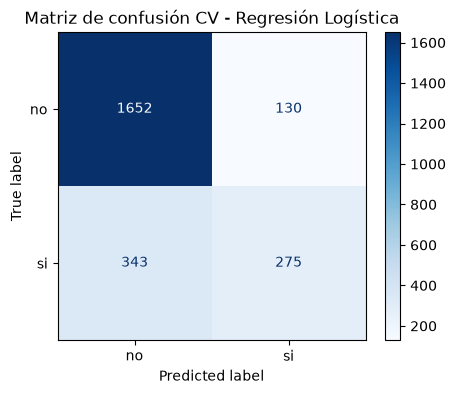


=== ÁRBOL DE DECISIÓN (validación cruzada, solo TRAIN) ===
              precision    recall  f1-score   support

          no       0.81      0.80      0.81      1782
          si       0.44      0.45      0.45       618

    accuracy                           0.71      2400
   macro avg       0.63      0.63      0.63      2400
weighted avg       0.71      0.71      0.71      2400



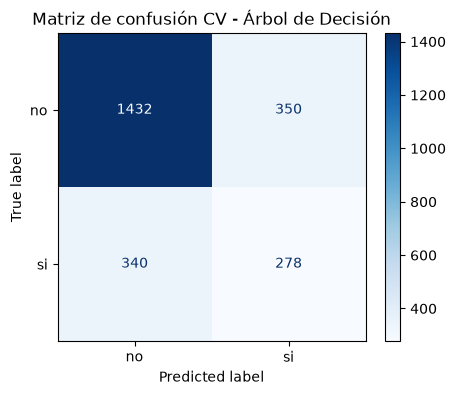


=== KNN (validación cruzada, solo TRAIN) ===
              precision    recall  f1-score   support

          no       0.78      0.92      0.84      1782
          si       0.53      0.27      0.35       618

    accuracy                           0.75      2400
   macro avg       0.65      0.59      0.60      2400
weighted avg       0.72      0.75      0.72      2400



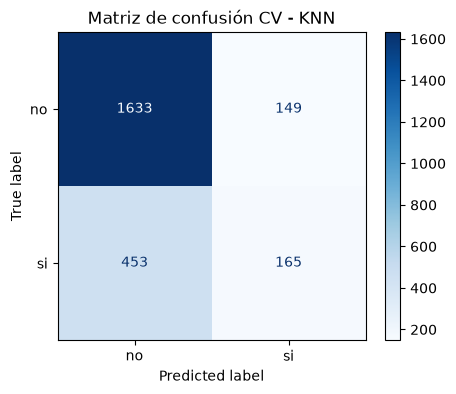


=== RANDOM FOREST (validación cruzada, solo TRAIN) ===
              precision    recall  f1-score   support

          no       0.82      0.94      0.88      1782
          si       0.71      0.41      0.52       618

    accuracy                           0.80      2400
   macro avg       0.76      0.68      0.70      2400
weighted avg       0.79      0.80      0.78      2400



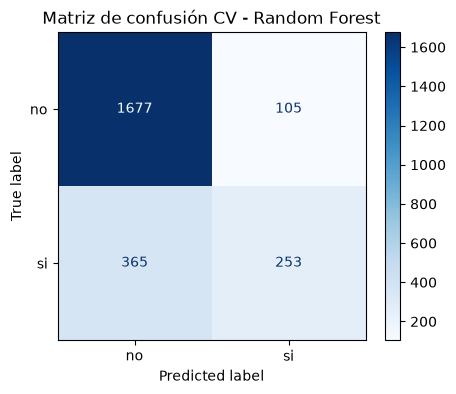

In [109]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Comparación didáctica de modelos: predicciones out-of-fold SOLO sobre train.
pipeline_lr = crear_pipeline(LogisticRegression(random_state=42, max_iter=1000), escalar=True) #por ser modelos basados en distancias
dt_model = crear_pipeline(DecisionTreeClassifier(random_state=42))
pipeline_knn = crear_pipeline(KNeighborsClassifier(n_neighbors=5), escalar=True) #por ser modelos basados en distancias
rf_model = crear_pipeline(RandomForestClassifier(random_state=42))

modelos_base = {
    'Regresión Logística': pipeline_lr,
    'Árbol de Decisión': dt_model,
    'KNN': pipeline_knn,
    'Random Forest': rf_model,
}

for nombre, modelo in modelos_base.items():
    y_pred_cv = cross_val_predict(modelo, X_train, y_train, cv=cv)
    print(f'\n=== {nombre.upper()} (validación cruzada, solo TRAIN) ===')
    print(classification_report(y_train, y_pred_cv))
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred_cv, cmap=plt.cm.Blues, ax=ax, values_format='d')
    ax.set_title(f'Matriz de confusión CV - {nombre}')
    plt.show()


In [121]:
from sklearn.model_selection import cross_validate

# Evaluación sin leakage: se reentrena el pipeline entero en cada fold de TRAIN.
for nombre, modelo in modelos_base.items():
    resultados = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring={'roc_auc': 'roc_auc', 'accuracy': 'accuracy'},
        n_jobs=-1
    )

    auc = resultados['test_roc_auc']
    accuracy = resultados['test_accuracy']


    print(
        f'{nombre}: '
        f'AUC de CV = {auc.mean():.4f} (+/- {auc.std():.4f}) | '
        f'Accuracy de CV = {accuracy.mean():.4f} (+/- {accuracy.std():.4f})',
    )


Regresión Logística: AUC de CV = 0.8168 (+/- 0.0269) | Accuracy de CV = 0.8029 (+/- 0.0137)
Árbol de Decisión: AUC de CV = 0.6267 (+/- 0.0215) | Accuracy de CV = 0.7125 (+/- 0.0172)
KNN: AUC de CV = 0.6932 (+/- 0.0261) | Accuracy de CV = 0.7492 (+/- 0.0116)
Random Forest: AUC de CV = 0.8065 (+/- 0.0252) | Accuracy de CV = 0.8042 (+/- 0.0140)


## Búsqueda de hiperparámetros sin balanceo (CV sobre train)

In [111]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Los cuatro modelos usan imputación agrupada + imputación general + one-hot DENTRO de CV.
# Las claves de hiperparámetros de estimadores encapsulados llevan prefijo clf__.
pipe_lr = crear_pipeline(LogisticRegression(random_state=42, max_iter=1000), escalar=True)
param_grid_lr = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__l1_ratio': [0.0, 1.0],
    'clf__penalty': ['elasticnet'],
    'clf__solver': ['saga'],
}
grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train, y_train)
print('=== 1. REGRESIÓN LOGÍSTICA ===')
print('Mejores parámetros:', grid_lr.best_params_)
print(f'Mejor AUC de CV: {grid_lr.best_score_:.4f}\n')

pipe_dt = crear_pipeline(DecisionTreeClassifier(random_state=42))
param_grid_dt = {
    'clf__max_depth': [None, 5, 10, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__criterion': ['gini', 'entropy'],
}
grid_dt = GridSearchCV(pipe_dt, param_grid_dt, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_dt.fit(X_train, y_train)
print('=== 2. ÁRBOL DE DECISIÓN ===')
print('Mejores parámetros:', grid_dt.best_params_)
print(f'Mejor AUC de CV: {grid_dt.best_score_:.4f}\n')

pipe_knn = crear_pipeline(KNeighborsClassifier(), escalar=True)
param_grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15],
    'clf__weights': ['uniform', 'distance'],
    'clf__metric': ['euclidean', 'manhattan'],
}
grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_knn.fit(X_train, y_train)
print('=== 3. KNN ===')
print('Mejores parámetros:', grid_knn.best_params_)
print(f'Mejor AUC de CV: {grid_knn.best_score_:.4f}\n')

pipe_rf = crear_pipeline(RandomForestClassifier(random_state=42))
param_grid_rf = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5, 10],
}
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train, y_train)
print('=== 4. RANDOM FOREST ===')
print('Mejores parámetros:', grid_rf.best_params_)
print(f'Mejor AUC de CV: {grid_rf.best_score_:.4f}\n')

resultados_grid = {
    'Regresión Logística': grid_lr,
    'Árbol de Decisión': grid_dt,
    'KNN': grid_knn,
    'Random Forest': grid_rf,
}
mejor_nombre_sin_balanceo = max(resultados_grid, key=lambda nombre: resultados_grid[nombre].best_score_)
print(f'Mejor sin balanceo: {mejor_nombre_sin_balanceo} ({resultados_grid[mejor_nombre_sin_balanceo].best_score_:.4f} AUC CV)')


/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logi

=== 1. REGRESIÓN LOGÍSTICA ===
Mejores parámetros: {'clf__C': 0.1, 'clf__l1_ratio': 1.0, 'clf__penalty': 'elasticnet', 'clf__solver': 'saga'}
Mejor AUC de CV: 0.8220

=== 2. ÁRBOL DE DECISIÓN ===
Mejores parámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_split': 10}
Mejor AUC de CV: 0.7794

=== 3. KNN ===
Mejores parámetros: {'clf__metric': 'manhattan', 'clf__n_neighbors': 15, 'clf__weights': 'distance'}
Mejor AUC de CV: 0.7459

=== 4. RANDOM FOREST ===
Mejores parámetros: {'clf__max_depth': 10, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
Mejor AUC de CV: 0.8102

Mejor sin balanceo: Regresión Logística (0.8220 AUC CV)


## Alternativa con SMOTETomek (dentro de la validación cruzada)

In [112]:
# Si no está instalada la librería, ejecutar esta celda en Jupyter:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [113]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# El balanceo SMOTETomek también debe ocurrir SOLO en la parte de entrenamiento
# de cada fold. Una variante de imblearn.Pipeline hace esto automáticamente.
# AVISO: SMOTE convencional puede interpolar las dummies de variables categóricas;
# para producción conviene estudiar SMOTENC o alternativas de ponderación de clases.

pipe_lr_smote = crear_pipeline(LogisticRegression(random_state=42, max_iter=1000), escalar=True, balancear=True)
param_grid_lr_smote = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid_lr_smote = GridSearchCV(pipe_lr_smote, param_grid_lr_smote, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr_smote.fit(X_train, y_train)
print('=== 1. REGRESIÓN LOGÍSTICA + SMOTETomek ===')
print('Mejores parámetros:', grid_lr_smote.best_params_)
print(f'Mejor AUC (CV): {grid_lr_smote.best_score_:.4f}\n')

pipe_dt_smote = crear_pipeline(DecisionTreeClassifier(random_state=42), balancear=True)
param_grid_dt_smote = {
    'clf__max_depth': [None, 5, 10, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__criterion': ['gini', 'entropy'],
}
grid_dt_smote = GridSearchCV(pipe_dt_smote, param_grid_dt_smote, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_dt_smote.fit(X_train, y_train)
print('=== 2. ÁRBOL DE DECISIÓN + SMOTETomek ===')
print('Mejores parámetros:', grid_dt_smote.best_params_)
print(f'Mejor AUC (CV): {grid_dt_smote.best_score_:.4f}\n')

pipe_knn_smote = crear_pipeline(KNeighborsClassifier(), escalar=True, balancear=True)
param_grid_knn_smote = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15],
    'clf__weights': ['uniform', 'distance'],
    'clf__metric': ['euclidean', 'manhattan'],
}
grid_knn_smote = GridSearchCV(pipe_knn_smote, param_grid_knn_smote, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_knn_smote.fit(X_train, y_train)
print('=== 3. KNN + SMOTETomek ===')
print('Mejores parámetros:', grid_knn_smote.best_params_)
print(f'Mejor AUC (CV): {grid_knn_smote.best_score_:.4f}\n')

pipe_rf_smote = crear_pipeline(RandomForestClassifier(random_state=42), balancear=True)
param_grid_rf_smote = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5, 10],
}
grid_rf_smote = GridSearchCV(pipe_rf_smote, param_grid_rf_smote, cv=cv, scoring='roc_auc', n_jobs=-1)
grid_rf_smote.fit(X_train, y_train)
print('=== 4. RANDOM FOREST + SMOTETomek ===')
print('Mejores parámetros:', grid_rf_smote.best_params_)
print(f'Mejor AUC (CV): {grid_rf_smote.best_score_:.4f}\n')

resultados_smote = {
    'Regresión Logística + SMOTETomek': grid_lr_smote,
    'Árbol de Decisión + SMOTETomek': grid_dt_smote,
    'KNN + SMOTETomek': grid_knn_smote,
    'Random Forest + SMOTETomek': grid_rf_smote,
}
print('=== COMPARACIÓN ENTRE CONFIGURACIONES, SOLO AUC DE VALIDACIÓN ===')
for nombre, grid in {**resultados_grid, **resultados_smote}.items():
    print(f'{nombre}: {grid.best_score_:.4f}')


=== 1. REGRESIÓN LOGÍSTICA + SMOTETomek ===
Mejores parámetros: {'clf__C': 0.01}
Mejor AUC (CV): 0.8175

=== 2. ÁRBOL DE DECISIÓN + SMOTETomek ===
Mejores parámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 5, 'clf__min_samples_split': 2}
Mejor AUC (CV): 0.7866

=== 3. KNN + SMOTETomek ===
Mejores parámetros: {'clf__metric': 'manhattan', 'clf__n_neighbors': 15, 'clf__weights': 'distance'}
Mejor AUC (CV): 0.7289

=== 4. RANDOM FOREST + SMOTETomek ===
Mejores parámetros: {'clf__max_depth': 10, 'clf__min_samples_split': 10, 'clf__n_estimators': 100}
Mejor AUC (CV): 0.8133

=== COMPARACIÓN ENTRE CONFIGURACIONES, SOLO AUC DE VALIDACIÓN ===
Regresión Logística: 0.8220
Árbol de Decisión: 0.7794
KNN: 0.7459
Random Forest: 0.8102
Regresión Logística + SMOTETomek: 0.8175
Árbol de Decisión + SMOTETomek: 0.7866
KNN + SMOTETomek: 0.7289
Random Forest + SMOTETomek: 0.8133


## Evaluación final: el test se usa una sola vez

=== EVALUACIÓN FINAL DEL GANADOR: Regresión Logística ===
AUC de CV para selección: 0.8220
Accuracy en test: 0.8133
AUC en test: 0.8099

Reporte de clasificación:
              precision    recall  f1-score   support

          no       0.82      0.96      0.88       446
          si       0.76      0.40      0.53       154

    accuracy                           0.81       600
   macro avg       0.79      0.68      0.70       600
weighted avg       0.81      0.81      0.79       600



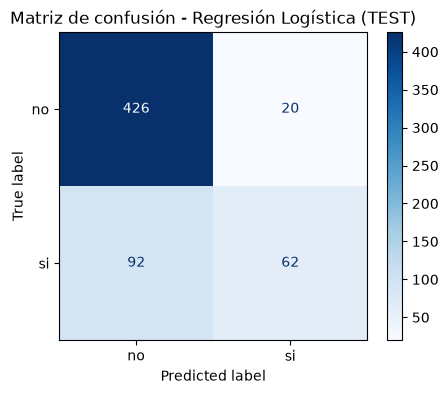

In [114]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, roc_auc_score, classification_report
import matplotlib.pyplot as plt

# SOLO AHORA, una vez seleccionada la configuración por CV, se usa el test.
todos_los_grid = {**resultados_grid, **resultados_smote}
mejor_nombre = max(todos_los_grid, key=lambda nombre: todos_los_grid[nombre].best_score_)
mejor_grid = todos_los_grid[mejor_nombre]
mejor_modelo_final = mejor_grid.best_estimator_  # Reajustado por GridSearchCV en TRAIN completo.

print(f'=== EVALUACIÓN FINAL DEL GANADOR: {mejor_nombre} ===')
print(f'AUC de CV para selección: {mejor_grid.best_score_:.4f}')
y_pred_final = mejor_modelo_final.predict(X_test)
y_score_final = mejor_modelo_final.predict_proba(X_test)[:, list(mejor_modelo_final.classes_).index('si')]
acc_final = accuracy_score(y_test, y_pred_final)
auc_final = roc_auc_score((y_test == 'si').astype(int), y_score_final)
print(f'Accuracy en test: {acc_final:.4f}')
print(f'AUC en test: {auc_final:.4f}\n')
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred_final))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, cmap=plt.cm.Blues, ax=ax, values_format='d')
ax.set_title(f'Matriz de confusión - {mejor_nombre} (TEST)')
plt.show()


# Checklist: Orden correcto y prevención del leakage

1. **Análisis exploratorio:** conocer columnas y calidad. Evitar que decisiones sobre variables se basen en patrones específicos de test.
2. **Reglas fijas de limpieza:** eliminar duplicados y etiquetas faltantes, descartar variables futuras o identificadores, aplicar reglas de dominio conocidas (rangos físicos, tarifas), codificaciones ordinales fijas y filtros de coherencia independientes de estadísticas aprendidas.
3. **Split estratificado train/test:** separar **antes** de calcular medianas, medias, modas, límites estadísticos, categorías del OHE o parámetros de escalado.
4. **Pipeline de preprocesamiento:** ajustar con train la imputación por grupos (edad y horas), otras imputaciones y OneHotEncoder; StandardScaler solo en modelos apropiados. El test se transforma con parámetros aprendidos en train, nunca con `fit` propio.
5. **Validación cruzada y GridSearchCV:** operar sobre X_train **original**, no sobre una versión imputada/encoded fuera del pipeline. Dentro de cada fold se ajusta su propio preprocesamiento. Si se usa SMOTETomek, debe estar dentro de `imblearn.Pipeline` y actuar exclusivamente en los datos de entrenamiento de cada fold.
6. **Selección del modelo:** escoger hiperparámetros y familia usando AUC de CV en train, sin mirar el test.
7. **Evaluación final:** usar X_test **una sola vez**, con el pipeline ganador completo.

> **Leakage de target:** `estado_cuenta_31_octubre` determina prácticamente `abandona` y no puede utilizarse ni como predictor, ni para imputar `satisfaccion`, ni para seleccionar registros. Por eso se elimina temprano y se evita el antiguo relleno basado en su valor.

> **Nota metodológica:** `SMOTETomek` tras one-hot puede generar categorías interpoladas; es una prueba didáctica preservada del original, pero conviene evaluar SMOTENC o ponderación de clases si se lleva el modelo a producción.
